![What Is Observability?](assets/banner-01.svg)

## The problem

You build a small AI assistant. A user complains: *"It gave me a wrong answer, and it was really slow."*

You open your code. It looks fine. You run it again and it works. **So what happened for that user?**

Without the right information you can only guess. **Observability** means your app leaves behind enough information that you can look back and see exactly what happened, step by step.

In this notebook we learn the four kinds of information an app can leave behind. No tools to install, no special knowledge needed.

## An everyday comparison: tracking a parcel

You already use observability every time you track a parcel.

| Parcel world | Software word | What it means |
|---|---|---|
| "Driver note: door locked, will retry" | **Log** | A short message about one moment |
| "We delivered 12,400 parcels today, average 2 days" | **Metric** | A number that summarizes many things |
| The full tracking history of **your** parcel | **Trace** | Everything that happened to **one** request, start to finish |
| One line in that history: "Left warehouse, 3 hours" | **Span** | One step inside a trace, with how long it took |

Keep this table in mind. Everything below is just these four ideas, applied to code.

## Our example: a tiny weather assistant

The assistant does two steps:

1. **Look up the weather** for a city. (We pretend to call a weather website.)
2. **Ask an AI model** whether you should carry an umbrella.

Read the code below first. It is plain Python.

In [1]:
import time

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv("../.env")  # loads OPENAI_API_KEY
client = OpenAI()

FAKE_WEATHER = {"Paris": "rainy, 14°C", "Tokyo": "sunny, 21°C", "London": "stormy, 11°C", "Dubai": "hot and dry, 35°C"}


def get_weather(city):
    time.sleep(0.5)  # pretend this is a slow website
    return FAKE_WEATHER[city]


def ask_ai(question):
    reply = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": question}],
    )
    return reply.choices[0].message.content


def weather_assistant(city):
    weather = get_weather(city)
    question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
    return ask_ai(question)


weather_assistant("Paris")

'Yes, you should carry an umbrella.'

It works. But if this ran on a server for thousands of users, we would see **nothing** about what happened inside. Let's add the four kinds of information, one at a time.

---

## 1. Logs: "what happened?"

A **log** is a short message your code writes at an important moment, with a timestamp. It is like the driver's note on your parcel.

We add three log lines: when a request starts, when we get the weather, and when the AI answers.

In [2]:
import logging

logging.basicConfig(format="%(asctime)s  %(levelname)s  %(message)s", datefmt="%H:%M:%S", force=True)
log = logging.getLogger("weather-assistant")
log.setLevel(logging.INFO)


def weather_assistant(city):
    log.info(f"request started for {city}")
    weather = get_weather(city)
    log.info(f"weather is {weather}")
    question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
    answer = ask_ai(question)
    log.info(f"AI answered: {answer}")
    return answer


weather_assistant("London");

17:54:28  INFO  request started for London


17:54:29  INFO  weather is stormy, 11°C


17:54:30  INFO  AI answered: Yes, you should carry an umbrella.


**Logs are great for details.** If something breaks, the log often says what went wrong.

**The weakness:** when many users use the app at the same time, log lines from different people get mixed together. It becomes hard to tell which lines belong to which user.

---

## 2. Metrics: "how much? how often? how fast?"

A **metric** is a number that summarizes many requests: how many requests we served, how long they took on average, how many failed. It is the "12,400 parcels delivered today" number.

Let's serve four cities and measure the time of each request.

In [3]:
import pandas as pd

log.setLevel(logging.WARNING)  # quiet the logs for now

timings = []
for city in ["Paris", "Tokyo", "London", "Dubai"]:
    start = time.time()
    weather_assistant(city)
    timings.append({"city": city, "seconds": round(time.time() - start, 2)})

timings = pd.DataFrame(timings)
print("requests served:  ", len(timings))
print("average time:     ", round(timings["seconds"].mean(), 2), "seconds")
print("slowest request:  ", timings["seconds"].max(), "seconds")

requests served:   4
average time:      1.2 seconds
slowest request:   1.29 seconds


Those three numbers are **metrics**. On a real system you would see them on a dashboard as charts, and you would get an alert if, for example, the average time went above 5 seconds.

**The weakness:** a metric says *"requests are slow"* but not *why*. Was it the weather website or the AI model? For that we need to see inside each request.

---

## 3. Traces and spans: "where did the time go?"

A **trace** is the full story of **one** request, like the tracking history of one parcel.
A trace is made of **spans**. Each span is one step: it has a **name**, a **start time** and an **end time**.

To create spans we use **OpenTelemetry**, the free, standard library for this. The pattern is always the same:

```python
with tracer.start_as_current_span("name of the step"):
    ...the code of that step...
```

Everything inside the `with` block is timed and recorded as one span. A span started inside another span becomes its **child**, so we get a tree: the whole request on top, the steps underneath.

Setting up OpenTelemetry takes four lines. You write them once per app:

In [4]:
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import SimpleSpanProcessor
from opentelemetry.sdk.trace.export.in_memory_span_exporter import InMemorySpanExporter

collected = InMemorySpanExporter()  # keep spans in memory so we can look at them
provider = TracerProvider()
provider.add_span_processor(SimpleSpanProcessor(collected))
tracer = provider.get_tracer("weather-assistant")

Now the same assistant, with one `with` block around the whole request and one around each step:

In [5]:
def weather_assistant(city):
    with tracer.start_as_current_span("weather_assistant"):  # the whole request = the trace
        with tracer.start_as_current_span("get_weather"):  # step 1 = a span
            weather = get_weather(city)
        with tracer.start_as_current_span("ask_ai"):  # step 2 = a span
            question = f"The weather in {city} is {weather}. Should I carry an umbrella? Answer in one short sentence."
            answer = ask_ai(question)
        return answer


collected.clear()
weather_assistant("Tokyo")

"No, you shouldn't carry an umbrella."

### What got recorded

Three spans. Notice the column **inside of**: both steps sit inside `weather_assistant`.

In [6]:
import lab

spans = collected.get_finished_spans()
lab.spans_frame(spans)[["step (span)", "inside of", "took"]]

,step (span),inside of,took
0,weather_assistant,"(nothing, this is the whole request)",1.17 s
1,get_weather,weather_assistant,0.50 s
2,ask_ai,weather_assistant,0.66 s


### The same trace as a picture

Every observability tool draws traces like this. Time runs left to right. The top bar is the whole request; the bars below are its steps.

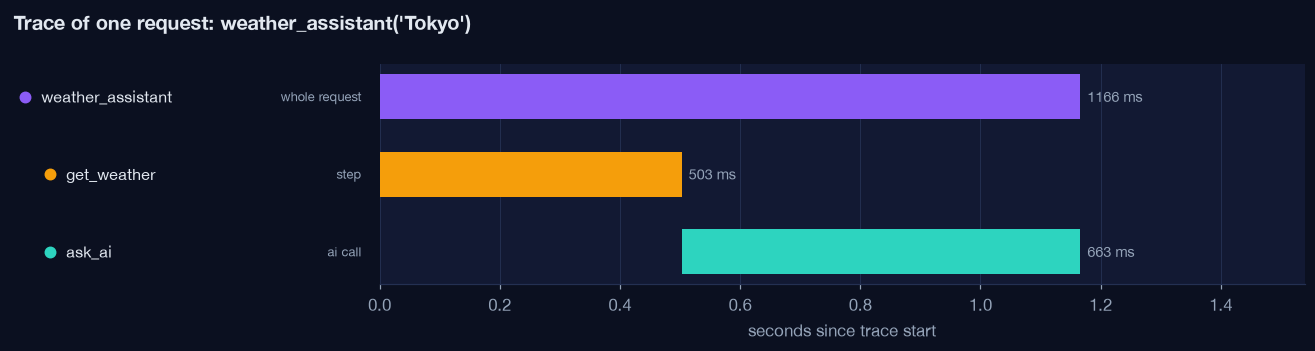

In [7]:
lab.draw_spans(spans, "Trace of one request: weather_assistant('Tokyo')")

Now we can answer the question metrics could not: **where did the time go?** You can see how much of the request was the weather lookup and how much was the AI model.

For AI apps, the AI step span can also record **which model** was used, **how many tokens** it read and wrote, and **how much it cost**. Tools like Langfuse and LangSmith add those for you automatically, as we will see next.

---

## Summary

| Signal | Question it answers | Parcel example | Weakness |
|---|---|---|---|
| **Log** | What happened at this moment? | "Door locked, will retry" | Hard to follow one user when many are mixed |
| **Metric** | How much, how often, how fast? | "12,400 parcels today" | Says *that* something is slow, not *why* |
| **Trace** | What happened to this one request? | The full tracking history | Needs a tool to view many of them |
| **Span** | How long did this one step take? | "Left warehouse, 3 hours" | Only useful inside its trace |

### Where does this data go?

So far the spans stayed inside this notebook. In real apps they are **sent to a tool** that stores them and shows them in a web page, so you can search and compare thousands of requests.

![How telemetry travels](assets/otel-pipeline.svg)

OpenTelemetry is the **common language**. Langfuse, LangSmith, Datadog and Dynatrace all understand it.

**Next:** [02 Langfuse](02_langfuse.ipynb). We send this exact assistant to Langfuse and see the trace in a real dashboard.